# 04 · Auditoría de equidad y ciclo de mitigación — Sprint 2 (F3)
> **Datos 100 % sintéticos.** AURORA SCORE y Vertex Financial Group son un caso ficticio con fines académicos (SCY1102, Duoc UC). Ejecutar antes `python src/pipeline.py`.

Tarjetas AUR-13, AUR-14, AUR-15, AUR-22. Criterio del plan: brecha máxima de 5 pp en aprobación entre grupos y regla del 80 %.

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import pandas as pd
from IPython.display import Image, display
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)
REP = RAIZ / "reports"; FIG = REP / "figures"
leer = lambda n: json.loads((REP / n).read_text(encoding="utf-8"))

In [2]:
e = leer('equidad_resumen.json')
pd.DataFrame({k: e[k]['veredicto'] for k in ['v1-base', 'v1-base (mismo volumen que v2)', 'v2-mitigado']})

,v1-base,v1-base (mismo volumen que v2),v2-mitigado
brecha_max_pp,22.3,13.53,1.49
atributo_peor,zona,zona,tramo_edad
dir_min,0.539,0.825,0.98
cumple_5pp,False,False,True
cumple_80,False,True,True
aprobado,False,False,True


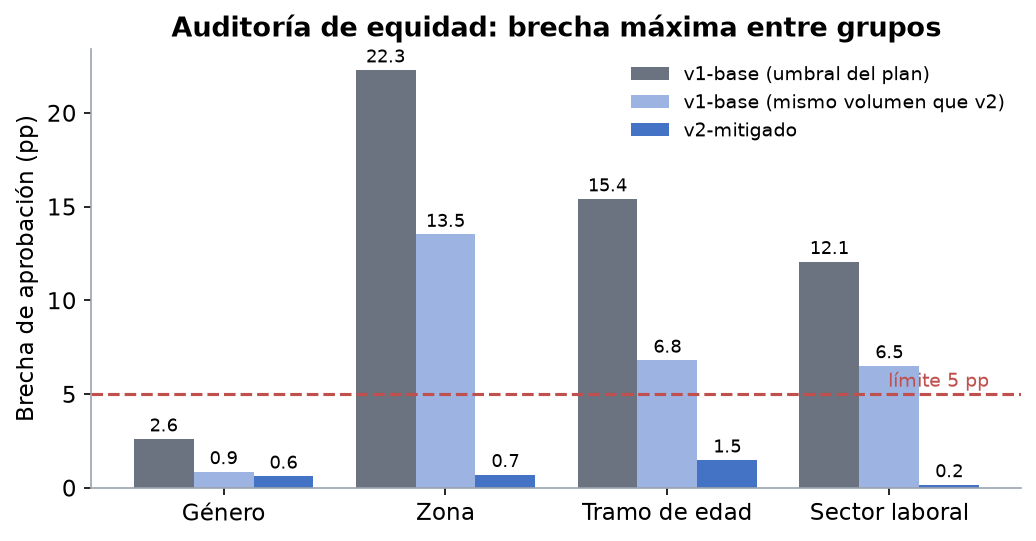

In [3]:
display(Image(FIG / '04_equidad_brechas.png', width=800))

## Detalle por grupo

In [4]:
g = pd.read_csv(REP / 'equidad_por_grupo.csv')
g.pivot_table(index=['atributo', 'grupo'], columns='modelo', values='tasa_aprobacion').round(3)

modelo                   v1-base  v1-base (mismo volumen que v2)  v2-mitigado
atributo       grupo                                                         
genero         F           0.430                           0.743        0.751
               M           0.457                           0.752        0.744
sector_laboral formal      0.501                           0.779        0.748
               informal    0.380                           0.713        0.747
tramo_edad     18-24       0.462                           0.754        0.752
               25-45       0.460                           0.759        0.752
               46-59       0.443                           0.739        0.737
               60+         0.308                           0.691        0.749
zona           rural       0.261                           0.637        0.753
               urbana      0.484                           0.772        0.746

## Ablación: cuánto aporta cada medida
Cada paso agrega una medida sobre el anterior; todos se comparan al mismo volumen de aprobación por país.

In [5]:
pd.read_csv(REP / 'ablacion_mitigacion.csv')

,paso,auc_test_real,brecha_max_pp,atributo_peor,dir_min,cumple
0,0. Base (v1),0.7448,13.53,zona,0.825,False
1,1. + conciliación de atraso y mora,0.8031,1.34,tramo_edad,0.982,True
2,2. + eliminación de proxies,0.8074,1.98,tramo_edad,0.974,True
3,3. + reponderación y cobertura (v2),0.8085,1.49,tramo_edad,0.980,True


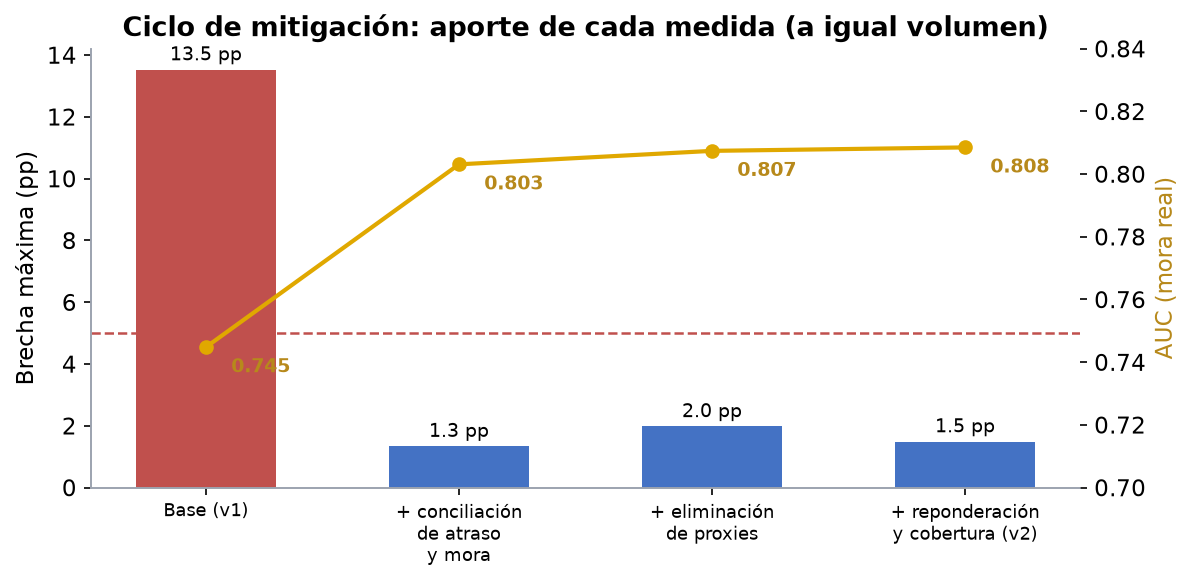

In [6]:
display(Image(FIG / '06_ablacion.png', width=800))

## KPI de inclusión efectiva

In [7]:
pd.DataFrame({k: e[k]['inclusion'] for k in ['v1-base', 'v1-base (mismo volumen que v2)', 'v2-mitigado']})

,v1-base,v1-base (mismo volumen que v2),v2-mitigado
pct_aprobados_subrepresentados,32.41,39.16,42.38
pct_solicitantes_subrepresentados,42.17,42.17,42.17
tasa_aprobacion_subrepresentados,34.09,69.43,75.14
tasa_aprobacion_resto,51.83,78.65,74.48


## Explicabilidad: factores de rechazo en lenguaje natural (RF-05)

In [8]:
x = pd.read_csv(REP / 'explicaciones_rechazos.csv')
print(f'{len(x):,} rechazos explicados; con 3 a 5 factores: {(x.n_factores >= 3).mean():.1%}')
for _, r in x.head(3).iterrows():
    print(f"\nSolicitud {r.solicitud_id}:")
    for i in range(1, 5):
        if isinstance(r.get(f'factor_{i}'), str): print('  -', r[f'factor_{i}'])

3,029 rechazos explicados; con 3 a 5 factores: 100.0%

Solicitud 30003:
  - El atraso promedio en servicios básicos (4,00) es mayor que en las solicitudes aprobadas (mediana 0,94).
  - La proporción de cuentas pagadas con atraso (1,00) es mayor que en las solicitudes aprobadas (mediana 0,42).
  - El número de recargas mensuales (1,00) es menor que en las solicitudes aprobadas (mediana 2,50).
  - El tiempo dedicado a revisar las condiciones (457,00) es mayor que en las solicitudes aprobadas (mediana 409,00).

Solicitud 30004:
  - El atraso promedio en servicios básicos (3,24) es mayor que en las solicitudes aprobadas (mediana 0,94).
  - La proporción de cuentas pagadas con atraso (0,88) es mayor que en las solicitudes aprobadas (mediana 0,42).
  - El ticket promedio de compra (15,23) es menor que en las solicitudes aprobadas (mediana 25,82).
  - El promedio mensual de compras en línea (0,83) es menor que en las solicitudes aprobadas (mediana 1,50).

Solicitud 30011:
  - El atraso promed

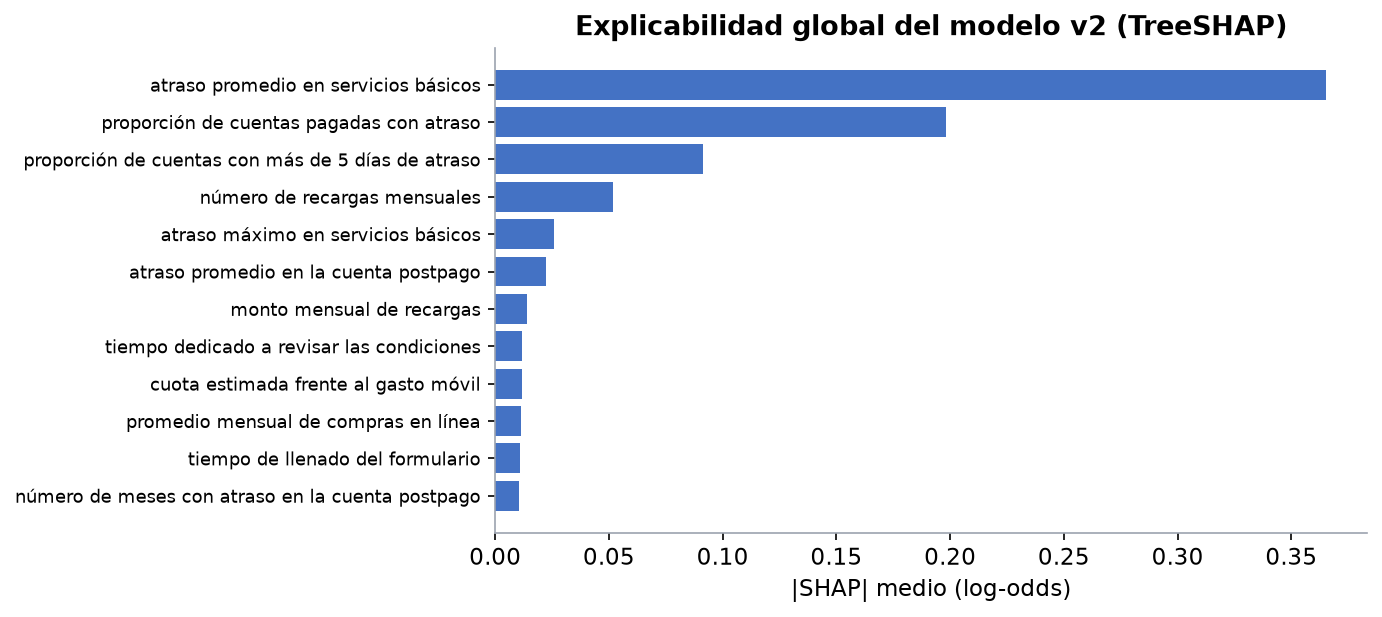

In [9]:
display(Image(FIG / '07_shap_global.png', width=750))

## Foco 7 del EP1: falla biométrica diferencial (no entra al modelo)

In [10]:
pd.DataFrame(e['falla_biometrica_primer_intento'])

,tramo_edad,sector_laboral
18-24,4.92,NaN
25-45,5.04,NaN
46-59,5.75,NaN
60+,12.11,NaN
formal,NaN,3.5
informal,NaN,8.3
